# Modello per la Classificazione di Contenuti Testuali
Giusti Nicola

**Obiettivo del Progetto:**

Sviluppare un modello AI basato su Natural Language Processing (NLP) per identificare e classificare automaticamente i diversi tipi di contenuti aziendali (email, documenti legali, report).

**Soluzione Tecnologica:**

Il progetto utilizza tecnologie NLP avanzate, sfruttando framework come Hugging Face, spaCy e TensorFlow, per implementare:
- Pre-elaborazione del testo: tokenizzazione, rimozione stopwords e normalizzazione.
- Modelli di classificazione: training di un modello supervisionato per riconoscere categorie di documenti (email, report, contratti, documenti di compliance, ecc.).
- Pipeline di analisi automatizzata: applicazione del modello su documenti in ingresso per assegnare etichette e metadati.

Il progetto si sviluppa in tre fasi:
1. **Fase 1** - Raccolta e Annotazione Dati: creazione di un dataset etichettato con diverse tipologie di documenti
2. **Fase 2** - Addestramento del Modello NLP: sviluppo e tuning del modello di classificazione.
3. **Fase 3** - Integrazione e Testing: validazione dei risultati.

## Impostazioni preliminari

In [ ]:
# 1. Installazione pacchetti
!pip install -U keras-hub keras tensorflow spacy -q
!python -m spacy download en_core_web_sm -q
!pip install --upgrade protobuf
!pip install Faker
!pip install --upgrade google-api-python-client google-auth-httplib2 google-auth-oauthlib protobuf

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# codice standard per evitare waning
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [ ]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import random
import re
import os
from faker import Faker
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import keras_hub as hub
import spacy
import kagglehub
from kagglehub import KaggleDatasetAdapter
import email
from sklearn.utils import shuffle
from datasets import load_dataset
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import AutoTokenizer
import seaborn as sns
import matplotlib.pyplot as plt

## DATASET

La creazione del dataset adeguato è fondamentale per ottenere il modello che vogliamo. Data la varietà di documenti che vogliamo classificare dobbiamo cercare di avere un dataset vario e più possibile bilanciato per non sotto o sovrastimare alcune tipologie.

### DATASET SINTETICO

Vista la varietà di label che possiamo dover analizzare per questo progetto e la necessità conseguente di combinare dataset differenti abbiamo deciso di partire creando un dataset sintetico bilanciato contenente tutte le label che vogliamo analizzare. Questo ci garantisce che il modello impari la struttura fissa (template) dei documenti aziendali.

Sono state generate anche due label *GARBAGE e UNSUPPORTED* per i documenti lavorativi non definiti o sbagliati. Inoltre utilizziamo una funzione *Faker* per simulare errori di battitura tipici dei documenti scritti.


NOTA: Abbiamo selezionato la lingua inglese perchè è quella che ci permette di combinare poi più dataset.

In [ ]:
# Inizializziamo Faker per dati realistici in inglese
fake = Faker('en_US')

CLASSI_DOCUMENTI = [
    "BUSINESS_EMAIL",
    "FINANCIAL_REPORT",
    "LEGAL_CONTRACT",
    "COMPLIANCE_DOC",
    "MEETING_MINUTES",
    "ADMIN_INVOICE",
    "OTHER",
    "UNSUPPORTED",
    "GARBAGE"
]

TEMPLATES = {
    "BUSINESS_EMAIL": [
        "Subject: {subject}\nDear {name},\nPlease find attached the documentation regarding {topic}.\nBest regards,\n{sender}",
        "Hi {name},\nI've updated the file for {topic} as we discussed in yesterday's meeting.\nLet me know if it works for you.\nCheers,\n{sender}",
        "Subject: URGENT - {subject}\nNotice: The new procedure for {topic} will be effective starting {date}.\nPlease review immediately.\nManagement"
    ],
    "FINANCIAL_REPORT": [
        "{month} {year} FINANCIAL REPORT\nTotal Revenue: ${value}\nOperating Costs: ${value2}\nNet Profit: ${value3}\nYoY Growth: {variation}%\nExecutive Summary: {topic}",
        "ANNUAL BALANCE SHEET {year}\nRevenue: ${value}\nEBITDA: ${value2}\nLiquidity Ratio: {ratio}\nTotal Debt: ${value3}"
    ],
    "LEGAL_CONTRACT": [
        "SERVICE AGREEMENT\nThis agreement is entered into on {date} between {company1} and {company2}.\nSection 1. Scope of Work: {topic}\nSection 2. Term: {duration} months\nSection 3. Consideration: ${value}\nSigned: {name} & {sender}",
        "NON-DISCLOSURE AGREEMENT (NDA)\nThe parties agree to maintain confidentiality regarding all information related to {topic} for a period of {duration} years."
    ],
    "COMPLIANCE_DOC": [
        "GDPR PRIVACY NOTICE\nIn accordance with Regulation (EU) 2016/679, personal data will be processed for the following purposes: {topic}.\nData subject rights: access, rectification, erasure.",
        "IT SECURITY POLICY\nSharing access credentials, using unauthorized personal devices, and transmitting sensitive data via unencrypted channels is strictly prohibited."
    ],
    "MEETING_MINUTES": [
        "MINUTES OF MEETING - {date}\nAttendees: {people}\nAgenda:\n1. {topic}\n2. Quarterly Review\n3. Action Items\nDecisions made: {decisions}\nNext meeting: {date2}",
        "CALL SUMMARY WITH {company2}\nDate: {date}\nTopics discussed: {topic}\nAction items: {actions}\nDeadline: {date2}"
    ],
    "ADMIN_INVOICE": [
        "INVOICE NO: {id}\nDate: {date}\nBill To: {name}\nDescription: {topic}\nTotal Amount: ${value}\nTax (10%): ${value2}\nDue Date: {date2}",
        "PURCHASE ORDER {id}\nVendor: {company1}\nItems: {topic}\nTotal: ${value}\nEstimated Delivery: {date}"
    ],
    "OTHER": [
        "Internal Memo: {topic}",
        "General announcement regarding {topic} scheduled for {date}.",
        "Note: please remember to {actions} before the end of the week."
    ],
    "UNSUPPORTED": [
        "RECIPE: {dish}\nIngredients: {ingredients}\nInstructions: {actions}. Cook for {duration} minutes.",
        "LATEST NEWS: {subject}\nReported by {name}.\nIn a surprising turn of events, {topic} has affected {company1}.",
        "WEATHER FORECAST: Expect {subject} in {company2} area. Temperatures around {variation} degrees."
    ],
    "GARBAGE": [
        "{gibberish}",
        "ERROR_404_NOT_FOUND - {id} - {id}\n!!!! {gibberish} !!!!",
        "SCANNED_PAGE_CORRUPTED: {short_gibberish}\n[IMAGE_DATA_MISSING]\n{gibberish}"
    ]
}

# Mapping delle variabili con logica dinamica
VAR_GEN = {
    "subject": lambda: fake.sentence(nb_words=4),
    "name": lambda: fake.name(),
    "sender": lambda: fake.name(),
    "company1": lambda: fake.company(),
    "company2": lambda: fake.company(),
    "topic": lambda: fake.catch_phrase(),
    "month": lambda: fake.month_name(),
    "year": lambda: random.choice(["2024", "2025", "2026"]),
    "date": lambda: fake.date(),
    "date2": lambda: fake.future_date().strftime("%Y-%m-%d"),
    "value": lambda: f"{random.randint(1000, 100000):,}",
    "value2": lambda: f"{random.randint(100, 5000):,}",
    "value3": lambda: f"{random.randint(50000, 1000000):,}",
    "variation": lambda: f"{random.randint(-20, 20)}",
    "ratio": lambda: f"{random.uniform(1.0, 2.5):.2f}",
    "duration": lambda: str(random.randint(6, 48)),
    "id": lambda: fake.bothify(text='??-#####'),
    "people": lambda: f"{fake.name()}, {fake.name()}, {fake.name()}",
    "decisions": lambda: fake.bs(),
    "actions": lambda: fake.bs(),
    "dish": lambda: fake.word().capitalize() + " " + fake.word(),
    "ingredients": lambda: f"{fake.word()}, {fake.word()}, {fake.word()}",
    "gibberish": lambda: " ".join([fake.password(length=random.randint(5, 12), special_chars=True) for _ in range(20)]),
    "short_gibberish": lambda: fake.password(length=15, digits=True, upper_case=True, special_chars=True)
}

In [ ]:
def generate_text(category):
    template = random.choice(TEMPLATES[category])
    placeholders = re.findall(r'\{(.*?)\}', template)

    text = template
    for ph in placeholders:
        if ph in VAR_GEN:
            val = VAR_GEN[ph]()
            text = text.replace("{"+ph+"}", str(val))
    return text

In [ ]:
def create_synthetic_dataset(n_samples=40000):
    dataset = []
    # Dividiamo per avere un dataset bilanciato
    samples_per_class = n_samples // len(CLASSI_DOCUMENTI)

    for cat in CLASSI_DOCUMENTI:
        print(f"Generating {samples_per_class} samples for {cat}:")
        for _ in range(samples_per_class):
            text = generate_text(cat)
            dataset.append({"text": text, "label": cat})

    return pd.DataFrame(dataset)

In [ ]:
df_synthetic = create_synthetic_dataset()

Generating 4444 samples for BUSINESS_EMAIL:
Generating 4444 samples for FINANCIAL_REPORT:
Generating 4444 samples for LEGAL_CONTRACT:
Generating 4444 samples for COMPLIANCE_DOC:
Generating 4444 samples for MEETING_MINUTES:
Generating 4444 samples for ADMIN_INVOICE:
Generating 4444 samples for OTHER:
Generating 4444 samples for UNSUPPORTED:
Generating 4444 samples for GARBAGE:


In [ ]:
df_synthetic

,text,label
0,"Hi Jacqueline Taylor,\nI've updated the file f...",BUSINESS_EMAIL
1,"Hi Brooke Stanley,\nI've updated the file for ...",BUSINESS_EMAIL
2,"Hi David Silva,\nI've updated the file for Ass...",BUSINESS_EMAIL
3,Subject: URGENT - High car key.\nNotice: The n...,BUSINESS_EMAIL
4,Subject: Difficult first language significant ...,BUSINESS_EMAIL
...,...,...
39991,ERROR_404_NOT_FOUND - dk-67247 - dk-67247\n!!!...,GARBAGE
39992,ERROR_404_NOT_FOUND - LC-28836 - LC-28836\n!!!...,GARBAGE
39993,@R&q5INn2P !6PoF Irq^V2Ge (QJiL7D8A7 %0X9ESrt ...,GARBAGE
39994,SCANNED_PAGE_CORRUPTED: )hUyF8alT8KHLF0\n[IMAG...,GARBAGE


### DATASET ENRON
Il dataset enron è un set reale di businness mail. Ne estraiamo i primi 15000 elementi per non scaricare tutto e sovraccaricare il codice.

In [ ]:
file_path = "emails.csv"

# Carichiamo il dataset (aggiungo un chunking/limit per evitare crash di RAM)
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "wcukierski/enron-email-dataset",
  file_path,
  pandas_kwargs={"nrows": 15000}
)

print(f"Dataset caricato: {df.shape}")

Using Colab cache for faster access to the 'enron-email-dataset' dataset.
Dataset caricato: (15000, 2)


In [ ]:
def parse_enron(raw_text):
    msg = email.message_from_string(raw_text)
    return msg.get_payload()

# Trasformazione
df['text'] = df['message'].apply(parse_enron)
df['label'] = 'BUSINESS_EMAIL' # Etichettatura automatica

# Mantengo solo le colonne necessarie
df_enron = df[['text', 'label']]

In [ ]:
df_enron

,text,label
0,Here is our forecast\n\n,BUSINESS_EMAIL
1,Traveling to have a business meeting takes the...,BUSINESS_EMAIL
2,test successful. way to go!!!,BUSINESS_EMAIL
3,"Randy,\n\n Can you send me a schedule of the s...",BUSINESS_EMAIL
4,Let's shoot for Tuesday at 11:45.,BUSINESS_EMAIL
...,...,...
14995,"Hi Eric,\n?\nI have a check for $630 but no lo...",BUSINESS_EMAIL
14996,I just talked to Dad about it. That is fine. ...,BUSINESS_EMAIL
14997,"I can do the tv but I am busy all weekend so, ...",BUSINESS_EMAIL
14998,"As you all are probably already aware, I am no...",BUSINESS_EMAIL


### DATASET LEGAL
Scarichiamo da HuggingFace il dataset EURLEX per la label legal contract. Visto che i contratti legali di questo codice hanno una struttura e una intestazione spesso molto tipizzata, abbiamo sceglto di aggiungere subito una funzione *clean_legal_text* che pulisce la label text del codice eliminando questa parte iniziale. Questo dovrebbe rendere il modello più robusto nel riconoscere un contratto legale dal contenuto e non dalla intestazione.

In [ ]:
# Puntiamo direttamente ai file Parquet generati da Hugging Face per la configurazione inglese ('en')
# La struttura degli URL di HF per i dati convertiti è standard:
base_url = "https://huggingface.co/datasets/nlpaueb/multi_eurlex/resolve/refs%2Fconvert%2Fparquet/en/train/0000.parquet"

df_legal = pd.read_parquet(base_url)
print("Dataset Legale caricato con successo via Parquet!")

# Prepariamolo per il nostro mix
df_legal = df_legal[['text', 'labels']]
df_legal['label'] = 'LEGAL_CONTRACT'

Dataset Legale caricato con successo via Parquet!


In [ ]:
def clean_legal_text(text):
    # 1. Rimuovi riferimenti alla Gazzetta Ufficiale e metadati iniziali
    # Spesso i documenti iniziano con codici tipo "L 123/1"
    text = re.sub(r'^[A-Z] \d+/\d+.*?\n', '', text, flags=re.IGNORECASE)

    # 2. Taglio del Preambolo
    # Cerchiamo il punto in cui finiscono i "considerando" e inizia il corpo
    markers = ["HAS ADOPTED THIS", "AGREES AS FOLLOWS", "Article 1", "SECTION 1"]
    for marker in markers:
        if marker in text:
            text = text.split(marker)[-1] # Prendiamo ciò che viene DOPO il marker
            break

    # 3. Normalizzazione spazi e caratteri speciali
    text = re.sub(r'\s+', ' ', text) # Rimuove newline e spazi multipli
    text = re.sub(r'\[.*?\]', '', text) # Rimuove note tra parentesi quadre

    # 4. Limitazione lunghezza (per evitare spreco di memoria)
    # Prendiamo i primi 2000 caratteri del "core" del documento
    return text[:2000].strip()

In [ ]:
# Applicazione al DataFrame
df_legal['text'] = df_legal['text'].apply(clean_legal_text)

In [ ]:
df_legal

,text,labels,label
0,REGULATION: Article 1 Annex I to Regulation (E...,"[2, 5, 10, 8, 3, 18, 15]",LEGAL_CONTRACT
1,REGULATION: Article 1 The names in the Annex t...,"[3, 18, 17, 6]",LEGAL_CONTRACT
2,DECISION: Article 1 1. For the purposes of Art...,"[17, 19, 10, 6, 15]",LEGAL_CONTRACT
3,REGULATION: Article 1 Regulation (EEC) No 3472...,"[7, 3, 17, 6]",LEGAL_CONTRACT
4,REGULATION: Article 1 The second subparagraph ...,"[17, 19, 6]",LEGAL_CONTRACT
...,...,...,...
10995,REGULATION: Article 1 For tenders notified fro...,"[3, 17, 5]",LEGAL_CONTRACT
10996,REGULATION: Article 1 The world price for ungi...,"[2, 17]",LEGAL_CONTRACT
10997,REGULATION: Article 1 The names in the Annex h...,"[3, 18, 17, 6]",LEGAL_CONTRACT
10998,REGULATION: Article 1 As from 13 July 1987 the...,"[3, 1]",LEGAL_CONTRACT


## DATASET RVL-CDIP
Questo dataset ci fornisce una serie di esempi reali di unsupported e altre label meno numerose. L'intento di inserire questo dataset nel nostro è di rafforzare il modello nel distinguere i documenti utili da classificare da quello che invece è rumore.

Anche qui visto che il dataset RVL-CDIP contiene alcune label che noi non utilizzeremo esplicitamente abbiamo creato una funzione preliminare per rimappare il dataset di partenza con le label necessarie per noi.


In [ ]:
# Carichiamo il dataset
ds_rvl = load_dataset("HAMMALE/rvl_cdip_OCR", split="train")

# Convertiamolo in DataFrame
df_rvl = ds_rvl.to_pandas()

# Vediamo le colonne disponibili
print("Colonne disponibili:", df_rvl.columns)

Colonne disponibili: Index(['image', 'width', 'height', 'category', 'ocr_words', 'word_boxes',
       'ocr_paragraphs', 'paragraph_boxes', 'label'],
      dtype='object')


In [ ]:
def process_hammale_ocr(df):
    # 1. Mapping delle label RVL-CDIP (Numerico -> Nome Classe)
    # 2:email, 11:invoice, 10:budget, 15:memo, 0:letter, 12:presentation
    mapping_rvl = {
        2: "BUSINESS_EMAIL",
        0: "BUSINESS_EMAIL",   # Spesso le 'letter' aziendali sono simili a email formali
        11: "ADMIN_INVOICE",
        10: "FINANCIAL_REPORT",
        15: "OTHER",            # Memos
        12: "OTHER"             # Presentations
    }

    # 2. Unione dei paragrafi
    # La colonna 'ocr_paragraphs' è una lista di stringhe. Le uniamo con un ritorno a capo.
    print("---Unione paragrafi OCR in corso---")
    df['text'] = df['ocr_paragraphs'].apply(
        lambda x: "\n".join(x) if isinstance(x, (list, np.ndarray)) else str(x)
    )

    # 3. Applicazione Label e filtraggio
    df['label'] = df['label'].map(mapping_rvl).fillna("UNSUPPORTED")

    # Pulizia righe: rimuoviamo testi troppo corti (possibili errori di scansione)
    df = df[df['text'].str.strip().str.len() > 20].copy()

    return df[['text', 'label']]

In [ ]:
# Applichiamo la trasformazione
df_rvl_clean = process_hammale_ocr(df_rvl)

---Unione paragrafi OCR in corso---


In [ ]:
df_rvl_clean['label'].value_counts()

,count
label,
UNSUPPORTED,5513
BUSINESS_EMAIL,1179
OTHER,1158
FINANCIAL_REPORT,588
ADMIN_INVOICE,584


## DATASET SEC EDGAR
In ultimo scarichiamo un Dataset grosso perfetto per report finanziari.

In [ ]:
print("Recupero dati finanziari/regolatori stabili:")
fin_ds = load_dataset("billsum", split="train")
df_fin = pd.DataFrame(fin_ds)

# Billsum ha le colonne 'text' e 'summary'. Usiamo 'text'.
df_fin = df_fin[['text']].copy()
df_fin['label'] = "FINANCIAL_REPORT"
print("Successo con Billsum")

# Pulizia rapida per garantire compatibilità
df_sec_clean = df_fin.dropna(subset=['text']).copy()
print(f"Dati finanziari finali: {len(df_sec_clean)} campioni.")

Recupero dati finanziari/regolatori stabili:
Successo con Billsum
Dati finanziari finali: 18949 campioni.


In [ ]:
df_sec_clean['label'].value_counts()

,count
label,
FINANCIAL_REPORT,18949


## DATASET CUMULATIVO
Adesso abbiamo una varietà di documenti da utilizzare per il nostro modello. Per rendere più flessibile la creazione del dataset su cui effettivamente lavoreremo abbiamo deciso di lavorare in due step:
- fondiamo tutti i dataset in un unico *df_master* che quindi avrà classi sbilanciate
- estraiamo da questo il dataset *df_all* che sarà quello su cui lavoriamo, e qui estraiamo in maniera bilanciata sulle classi meno numerose.

In [ ]:
# Uniamo tutti i DataFrame in uno solo
frames = [df_synthetic, df_enron, df_legal, df_rvl_clean, df_sec_clean]
df_master = pd.concat(frames, ignore_index=True)

# Verifichiamo la situazione attuale delle classi
print("--- Distribuzione nel Master Dataset ---")
print(df_master['label'].value_counts())

--- Distribuzione nel Master Dataset ---
label
FINANCIAL_REPORT    23981
BUSINESS_EMAIL      20623
LEGAL_CONTRACT      15444
UNSUPPORTED          9957
OTHER                5602
ADMIN_INVOICE        5028
COMPLIANCE_DOC       4444
MEETING_MINUTES      4444
GARBAGE              4444
Name: count, dtype: int64


### ESTRAZIONE DATASET FINALE

In [ ]:
def create_balanced_dataset(df):
    # 1. Troviamo il numero minimo di campioni tra le classi
    class_counts = df['label'].value_counts()
    min_samples = class_counts.min()
    min_class = class_counts.idxmin()

    print(f"\nClasse meno numerosa: '{min_class}' con {min_samples} campioni.")
    print(f"Bilancio tutte le classi a {min_samples} campioni.\n")

    balanced_list = []

    # 2. Per ogni categoria, estraiamo esattamente min_samples
    for cat in df['label'].unique():
        class_subset = df[df['label'] == cat]
        # Estraiamo i campioni casualmente
        balanced_subset = class_subset.sample(n=min_samples, random_state=42)
        balanced_list.append(balanced_subset)

    # 3. Unione e Shuffle finale
    df_balanced = pd.concat(balanced_list, ignore_index=True)
    df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

    print(f"Dataset df_all creato: {len(df_balanced)} righe totali ({len(df['label'].unique())} classi x {min_samples}).")
    return df_balanced

# Generiamo il dataset per il modello
df_all = create_balanced_dataset(df_master)


Classe meno numerosa: 'COMPLIANCE_DOC' con 4444 campioni.
Bilancio tutte le classi a 4444 campioni.

Dataset df_all creato: 39996 righe totali (9 classi x 4444).


In [ ]:
df_all['label'].value_counts()

,count
label,
FINANCIAL_REPORT,4444
COMPLIANCE_DOC,4444
OTHER,4444
LEGAL_CONTRACT,4444
MEETING_MINUTES,4444
ADMIN_INVOICE,4444
GARBAGE,4444
UNSUPPORTED,4444
BUSINESS_EMAIL,4444


### Esempio documenti in analisi
Mandiamo in stampa un esempio di testo per ogni tipologia di documento.

In [ ]:
def print_label_samples(df, text_col='text', label_col='label', max_len=150):

    print(f"{'LABEL':<20} | {'SAMPLE TEXT'}")
    print("-" * 80)

    # Otteniamo le label uniche ordinate
    unique_labels = sorted(df[label_col].unique())

    for label in unique_labels:
        # Estraiamo un esempio casuale per la label corrente
        sample = df[df[label_col] == label][text_col].iloc[0]

        # Pulizia base: rimuoviamo i ritorni a capo per la visualizzazione
        sample_clean = str(sample).replace('\n', ' ').strip()

        # Tronchiamo se il testo è troppo lungo
        if len(sample_clean) > max_len:
            sample_clean = sample_clean[:max_len] + "..."

        print(f"{label:<20} | {sample_clean}")

# Esecuzione
print_label_samples(df_all)

LABEL                | SAMPLE TEXT
--------------------------------------------------------------------------------
ADMIN_INVOICE        | INVOICE NO: OF-44208 Date: 1993-01-09 Bill To: Theodore Harrison Description: Quality-focused transitional Local Area Network Total Amount: $37,276 Ta...
BUSINESS_EMAIL       | Hey Danny,  Here is a prospective roster for Flag Football.  All are Enron employees.   Eric Bass Brian Hoskins Tim Blanchard Matt Lenhart Luis Mena J...
COMPLIANCE_DOC       | IT SECURITY POLICY Sharing access credentials, using unauthorized personal devices, and transmitting sensitive data via unencrypted channels is strict...
FINANCIAL_REPORT     | ANNUAL BALANCE SHEET 2025 Revenue: $42,457 EBITDA: $3,788 Liquidity Ratio: 1.78 Total Debt: $716,731
GARBAGE              | F^m1X9ns wi0aNNfL$d i+5LSKn #4GcA+g @1fuVb )D7SWyl %3TMe !q5Dge @W#y(gVs^4lB swqMc1Mc$B (7K)o #z8E(kP q)6Mh H)!7K8m% !8YY1Ef5#5 ^b2fLoY GA#(6Bw 5)b0#F...
LEGAL_CONTRACT       | SERVICE AGREEMENT This agreem

## PANNELLO DI CONTROLLO

Impostiamo qui i valori degli iperparametri della parte di pulizia e addestramento del modello, in modo di poter più facilmente controllare il lavoro.

In [ ]:
BATCH_SIZE=28
LEARNING_RATE=3e-5
PATIENCE=2
EPOCHS=10

# Pulizia del dataset

Creiamo una classe *DocumentProcessor* di funzioni che mi pulisce i testi del dataset e li prepara per fornirli al modello. Abbiamo scelto di creare una classe per rendere più facile implementare successivi utilizzi su ulteriori documenti.

In più, visto che abbiamo scelto di utilizzare come modello **DistilBERT** che ha già un meccanismo di attenzione e un tokenizer interni, faremo una pulizia conservativa del nostro dataset in modo da cercare di mantenere le caratteristiche semantiche del testo che possono dare forza al nostro modello.

In [ ]:
class DocumentProcessor:
    def __init__(self, model_ckpt="distilbert-base-uncased"):
        # Carichiamo spacy solo per la pulizia base (punteggiatura/spazi)
        # Disabilitiamo tutto il resto per la massima velocità
        self.nlp = spacy.load("en_core_web_sm", disable=["parser", "ner", "lemmatizer", "textcat"])
        self.tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
        self.label_encoder = LabelEncoder()
        self.mapping = None

    def clean_text_for_transformer(self, text):

        if not isinstance(text, str) or len(text.strip()) < 5:
            return "empty_document_or_corrupted"

        # 1. Normalizzazione base: minuscolo e rimozione spazi extra
        text = text.lower().strip()

        # 2. Rimozione di pattern che disturbano i Transformer (es: link, email lunghe, caratteri speciali ripetuti)
        text = re.sub(r'https?://\S+|www\.\S+', '[URL]', text)
        text = re.sub(r'\S+@\S+', '[EMAIL]', text)
        text = re.sub(r'[^a-zA-Z0-9\s.,!?]', '', text) # Teniamo punteggiatura essenziale

        # 3. Uso di spaCy solo per normalizzare spazi e raggruppare token
        # Nota: NON rimuoviamo le stop-words e NON facciamo lemmatizzazione
        doc = self.nlp(text)
        cleaned = " ".join([token.text for token in doc if not token.is_space])

        return cleaned if len(cleaned) > 10 else "low_content_noise"

    def process(self, df, training=True):
        print("--- Starting DocAI Pipeline ---")

        # Gestione corretta del Label Encoding
        if training:
            df['label_idx'] = self.label_encoder.fit_transform(df['label'])
            self.mapping = dict(zip(range(len(self.label_encoder.classes_)), self.label_encoder.classes_))
        else:
            df['label_idx'] = self.label_encoder.transform(df['label'])

        print("---Cleaning text (keeping context)---")
        df['text'] = df['text'].apply(self.clean_text_for_transformer)

        print("---Tokenizing---")
        hf_ds = Dataset.from_pandas(df)

        # Usiamo il tokenizer di DistilBERT che gestisce già tutto (truncation, padding)
        tokenized_ds = hf_ds.map(
            lambda x: self.tokenizer(
                x["text"],
                padding="max_length",
                truncation=True,
                max_length=512
            ),
            batched=True,
            remove_columns=[c for c in df.columns if c != 'label_idx']
        )
        return tokenized_ds

In [ ]:
processor = DocumentProcessor()

Di seguito abbiamo vari punti importanti del codice:
- nella divisione del dataset nei tre componenti Train, Test e Val utilizziamo *stratify* per non avere problemi di sbilanciamento tra le classi.
- applichiamo il processor ai dataset splittati e creiamo gli array tokenizzati per il modello
- ricreiamo i dataset con la funzione *create_dataset* che contiene lo shuffle per fornire dati al modello non ordinati e AUTOTUNE perchè il modello prepari il batch successivo mentre lavora sul batch corrente. Questo ci permette di gestire meglio la RAM e velocizzare il training.

In [ ]:
# 1. Split: Train (70%) e il resto (30%)
df_train, df_temp = train_test_split(
    df_all,
    test_size=0.3,
    random_state=42,
    stratify=df_all['label']
)

# 2. Split del resto: Val (15%) e Test (15%)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=42,
    stratify=df_temp['label']
)

# Reset degli indici per tutti (Fondamentale per la sincronia)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f"Dimensioni: Train {len(df_train)}, Val {len(df_val)}, Test {len(df_test)}")

Dimensioni: Train 27997, Val 5999, Test 6000


In [ ]:
# Funzione di utilità per trasformare il DF in array pronti per il modello
def prepare_model_inputs(df, processor):
    processed = processor.process(df)
    processed.set_format(type="numpy", columns=["input_ids", "attention_mask", "label_idx"])

    X_ids = np.array(processed["input_ids"], dtype="int32")
    X_mask = np.array(processed["attention_mask"], dtype="int32")
    y = np.array(processed["label_idx"], dtype="int32")

    return X_ids, X_mask, y

# Prepariamo i 3 set
X_ids_train, X_mask_train, y_train = prepare_model_inputs(df_train, processor)
X_ids_val, X_mask_val, y_val = prepare_model_inputs(df_val, processor)
X_ids_test, X_mask_test, y_test = prepare_model_inputs(df_test, processor)

--- Starting DocAI Pipeline ---
---Cleaning text (keeping context)---
---Tokenizing---


Map:   0%|          | 0/27997 [00:00<?, ? examples/s]

--- Starting DocAI Pipeline ---
---Cleaning text (keeping context)---
---Tokenizing---


Map:   0%|          | 0/5999 [00:00<?, ? examples/s]

--- Starting DocAI Pipeline ---
---Cleaning text (keeping context)---
---Tokenizing---


Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

In [ ]:
def create_dataset(ids, mask, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(({"token_ids": ids, "padding_mask": mask}, labels))
    if shuffle: ds = ds.shuffle(2000)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
train_dataset = create_dataset(X_ids_train, X_mask_train, y_train, shuffle=True)
val_dataset = create_dataset(X_ids_val, X_mask_val, y_val)
test_dataset = create_dataset(X_ids_test, X_mask_test, y_test)

# MODELLO

Per il modello abbiamo deciso di adottare DistilBERT valutando il rapporto efficacia/peso del modello che vogliamo creare.
Il modello ottenuto deve essere sufficientemente veloce da addestrare sul nostro dataset ma vogliamo ottenere anche delle metriche efficaci per documenti fortemente tipizzati come quelli lavorativi.

Nel modello abbiamo impostato *preprocessor=None* visto che abbiamo già creato e applicato il nostro prerprocessor

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow" # Forza il backend

import keras
import keras_hub

print(f"KerasHub versione: {keras_hub.__version__}")

KerasHub versione: 0.29.0


In [ ]:
# Caricamento Modello
# Abilita il calcolo a precisione mista
keras.mixed_precision.set_global_policy("mixed_float16")
model = keras_hub.models.DistilBertClassifier.from_preset(
    "hf://distilbert-base-uncased",
    num_classes=len(processor.label_encoder.classes_),
    preprocessor=None,
    activation="softmax"
)

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    metrics=["accuracy"],
    jit_compile=False # Stiamo lavorando su Colab T4
)

# Callbacks: Early Stopping e Salvataggio Miglior Modello
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath="best_docai_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

# Esecuzione Training
print("Inizio addestramento con Early Stopping:")
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Inizio addestramento con Early Stopping:
Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 926s 905ms/step - accuracy: 0.9551 - loss: 0.2057 - val_accuracy: 0.9753 - val_loss: 0.0794
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 873s 873ms/step - accuracy: 0.9811 - loss: 0.0573 - val_accuracy: 0.9742 - val_loss: 0.0783
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 945s 945ms/step - accuracy: 0.9873 - loss: 0.0380 - val_accuracy: 0.9785 - val_loss: 0.0804
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 871s 871ms/step - accuracy: 0.9906 - loss: 0.0287 - val_accuracy: 0.9753 - val_loss: 0.1007


## METRICHE DEL MODELLO
Le metriche del modello sono molto soddisfacenti:
- abbiamo precision e racall molto alte (0.96-1.00) su quasi tutte le tipologie di documenti. Questo vuol dire che effettivamente il dataset utilizzato ha tipologie valide di documenti da studiare, ma anche che il nostro modello è riuscito a coglierne molto bene le caratteristiche.
- le label *OTHER e UNSUPPORTED* hanno ovviamente una distinzione più difficile (distinguere un documento aziendale generico da un contenuto non supportato) e le metriche delle due classi confermano che tra loro resta confusione. Sembra che una quota di documenti OTHER finisca UNSUPPORTED e viceversa.


In [ ]:
print("\n--- Valutazione Finale sul Test Set ---")
y_pred_probs = model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)

# Report dettagliato
print(classification_report(y_test, y_pred, target_names=processor.label_encoder.classes_))


--- Valutazione Finale sul Test Set ---
215/215 ━━━━━━━━━━━━━━━━━━━━ 61s 280ms/step
                  precision    recall  f1-score   support

   ADMIN_INVOICE       0.94      0.98      0.96       666
  BUSINESS_EMAIL       0.99      0.97      0.98       666
  COMPLIANCE_DOC       1.00      1.00      1.00       667
FINANCIAL_REPORT       1.00      0.98      0.99       667
         GARBAGE       1.00      1.00      1.00       667
  LEGAL_CONTRACT       1.00      1.00      1.00       667
 MEETING_MINUTES       1.00      1.00      1.00       667
           OTHER       0.95      0.95      0.95       666
     UNSUPPORTED       0.92      0.91      0.92       667

        accuracy                           0.98      6000
       macro avg       0.98      0.98      0.98      6000
    weighted avg       0.98      0.98      0.98      6000



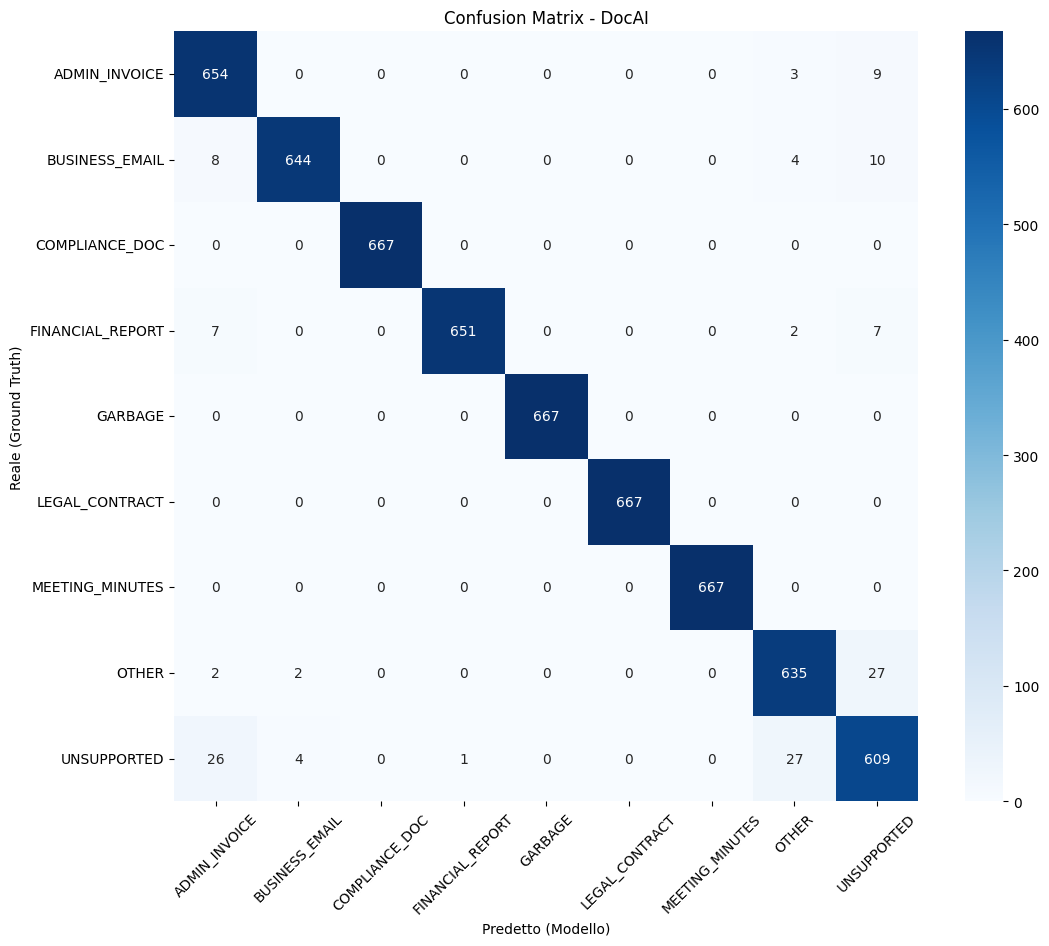

In [ ]:
# 1. Estraiamo le etichette REALI dal Test Set (quello usato per il report)
y_true_test = np.concatenate([y for x, y in test_dataset], axis=0)

# 2. Generazione nomi delle classi
target_names = [processor.label_encoder.classes_[i] for i in range(len(processor.label_encoder.classes_))]

# 3. Creazione Matrice
cm = confusion_matrix(y_true_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names,
            yticklabels=target_names)

plt.xlabel('Predetto (Modello)')
plt.ylabel('Reale (Ground Truth)')
plt.title('Confusion Matrix - DocAI')
plt.xticks(rotation=45)
plt.show()

## TEST DI ESEMPIO

Mandiamo in stampa 10 esempi di documenti del test set con gli output espliciti del modello in modo da rendere più evidente dove il modello si mostri efficace e dove invece sbagli.

Questo ci può mostrare anche che sulle classi più difficili (OTHER e UNSUPPORTED, vedi sopra) il modello ha livelli di soglia molto più bassi per le altre classi, confemando una difficoltà su quei specifici documenti ma un comportamento complessivo robusto.

In [ ]:
def inspect_doc_samples_final(model, X_ids, X_mask, df_test, label_encoder, n_examples=10):
    categories = label_encoder.classes_

    # Selezioniamo indici casuali basati sulla lunghezza effettiva del set di test (4500)
    test_size = len(X_ids)
    random_indices = random.sample(range(test_size), n_examples)

    print(f"=== ISPEZIONE CASUALE DOCUMENTI ({n_examples} ESEMPI) ===\n")

    for i, idx in enumerate(random_indices):
        # 1. Recupero dal DataFrame (che deve avere l'indice resettato)
        raw_text = df_test.iloc[idx]['text']
        true_label = df_test.iloc[idx]['label']

        # 2. Predizione usando gli array NumPy allineati
        sample_input = {
            "token_ids": np.expand_dims(X_ids[idx], axis=0),
            "padding_mask": np.expand_dims(X_mask[idx], axis=0)
        }

        probs = model.predict(sample_input, verbose=0)[0]
        pred_idx = np.argmax(probs)
        pred_label = categories[pred_idx]
        confidence = probs[pred_idx]

        # 3. Visualizzazione
        print(f"ESEMPIO {i+1} (Posizione nel Test Set: {idx}):")
        preview = str(raw_text).replace('\n', ' ').strip()
        print(f"TESTO: \"{preview[:300]}...\"")

        is_match = "✅" if true_label == pred_label else "❌"

        print(f"LABEL REALE:    {true_label}")
        print(f"PREDIZIONE:     {pred_label} ({confidence*100:.1f}%) {is_match}")

        # Top 3 probabilità
        top_indices = np.argsort(probs)[-3:][::-1]
        print("\nTOP 3 PROBABILITÀ:")
        for ti in top_indices:
            star = "⭐" if categories[ti] == pred_label else "  "
            print(f"  {star} {categories[ti]:<20}: {probs[ti]*100:>5.1f}%")

        print("-" * 80 + "\n")


In [ ]:
inspect_doc_samples_final(model, X_ids_test, X_mask_test, df_test, processor.label_encoder)

=== ISPEZIONE CASUALE DOCUMENTI (10 ESEMPI) ===

ESEMPIO 1 (Posizione nel Test Set: 3844):
TESTO: "may 2025 financial report total revenue 7,420 operating costs 2,461 net profit 495,921 yoy growth 10 executive summary total 247 solution..."
LABEL REALE:    FINANCIAL_REPORT
PREDIZIONE:     FINANCIAL_REPORT (99.9%) ✅

TOP 3 PROBABILITÀ:
  ⭐ FINANCIAL_REPORT    :  99.9%
     ADMIN_INVOICE       :   0.0%
     BUSINESS_EMAIL      :   0.0%
--------------------------------------------------------------------------------

ESEMPIO 2 (Posizione nel Test Set: 2021):
TESTO: "scannedpagecorrupted mmrlq7jgbt3oc imagedatamissing s7zyb s0vx y1tn 9jmol whmvvuo8n kou9fbr yj69gxjecnt 6ugctcl fh32tp EMAIL 7pwlgiw EMAIL cvasyzn2i l4ug zoiuwc2 EMAIL xyo4qvq 3n8hweaxrt 84ql 0xrh..."
LABEL REALE:    GARBAGE
PREDIZIONE:     GARBAGE (99.9%) ✅

TOP 3 PROBABILITÀ:
  ⭐ GARBAGE             :  99.9%
     BUSINESS_EMAIL      :   0.0%
     ADMIN_INVOICE       :   0.0%
--------------------------------------------------

## CONCLUSIONI

Possiamo ritenerci soddisfatti del modello. Le metriche ottenute sono molto soddisfacenti come già detto, e gli esempi espliciti di test ci danno visivamente un buon risultato delle applicazioni del modello.

Ovviamente la forza del modello sta nella scelta dei **DistilBERT** come modello preaddestrato, permettendoci di sfruttare tutti i punti di forza di questo Transformer Encoder.

L'altro aspetto di forza del nostro modello è dato dal dataset. Aver utilizzato insieme più dataset su label differenti, ed averli completati con un dataset sintetico di nostra creazione ci ha permesso di lavorare su un set di documenti adeguato. Non abbiamo avuto problemi di sbilanciamento tra le classi, cosa che ci avrebbe dato non pochi problemi nell'affinamento del modello. Abbiamo potuto lavorare su un dataset con tutte le label che volevamo presenti.

In più abbiamo cercato di strutturare il codice di creazione del dataset e di pulizia e immissione del modello in maniera più leggibile e flessibile possibile, in modo che si possa in eventuali step successivi aggiungere label e dataset per potenziare ulteriormente il modello.